# Splitting the boiling-point model error by cause

**Question.** How well does the simple barometric formula predict the boiling point of water at different altitudes, compared with published values?

**What this notebook does.** It takes a barometric pressure model (an isothermal atmosphere and the ISA troposphere) and four thermodynamic variants of the Clausius-Clapeyron boiling-point relation. It computes the boiling temperature at each altitude and compares it with two **computed** reference series from the dataset:

- the Engineering ToolBox boiling-point-versus-altitude table (its method is not stated in the dataset), and
- IAPWS-IF97 saturation temperature at the ISA pressure for each altitude.

The four variants are: constant enthalpy anchored at 373.124 K (A373.124), constant enthalpy anchored at 373.15 K (A373.15), an effective constant enthalpy fitted to IAPWS-IF97 saturation (B), and direct IAPWS-IF97 saturation inversion (C).

**Important limitation.** The dataset contains no measured boiling points. Every number below is an agreement statistic against a computed reference, not an accuracy claim against measurement.

**Data.** `mini_demo_data.json` is a curated subset of the dependency file `full_data_out.json` (43 of its 125 altitudes, every third one plus 9144 m). It is loaded from GitHub with a local fallback.

**Run time.** Well under a minute on a laptop, including the package install in a clean environment. The notebook writes its outputs (`results/`, `logs/`, `method_out.json`) into the working directory.


In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# iapws and loguru are NOT pre-installed on Colab, always install them
_pip('iapws==1.5.5')
_pip('loguru==0.8.0')

# numpy, scipy and matplotlib are pre-installed on Colab; install locally at Colab's exact versions only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')


## Imports and figure style

The original import block is kept as written. `matplotlib` is added for the results plots, together with the shared figure style of this run.


In [2]:
import gc
import json
import math
import sys
from pathlib import Path

import numpy as np
from iapws import IAPWS97
from loguru import logger
from scipy.optimize import brentq
import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})


Matplotlib is building the font cache; this may take a moment.


## Data loading

The notebook reads the curated data from GitHub. If that is unavailable (for example before the repository is published), it falls back to the local `mini_demo_data.json`.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-fde7b3-simple-barometric-model-vs-boiling-point/main/round-2/experiment-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


## Configuration

The tunable parameters are set here. The values are the smallest that still cover every altitude band (0-3 km, 3-6 km, 6-9 km), so the first test run is quick. Set `ALTITUDE_STRIDE = 1` to use every altitude in the curated file.


In [5]:
# Tunable parameters. Start at the minimum that still covers every altitude band.
ALTITUDE_STRIDE = 1  # keep every Nth altitude of the curated file; 1 = all 43 altitudes in mini_demo_data.json
FIT_N = 31           # points in the effective-enthalpy fit (variant B); original value

# Thin both reference series the same way so their altitudes still match
for _ds in data["datasets"]:
    _ds["examples"] = _ds["examples"][::ALTITUDE_STRIDE]
print(f"Altitudes used per series: {len(data['datasets'][0]['examples'])}")

Altitudes used per series: 43


## 1. Paths, logging and constants

Physical constants are the ones given in the original script, with their sources. The notebook uses the working directory in place of the script's own folder.


In [6]:
# Notebook version: __file__ is not defined in a notebook, so the working directory is used instead.
WS = Path.cwd()
RESULTS = WS / "results"
LOGS = WS / "logs"
LOGS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(LOGS / "run.log", rotation="30 MB", level="DEBUG")

# ---------------------------------------------------------------- constants
P0 = 101325.0            # Pa, ISA sea-level pressure (ISO 2533:1975)
T0 = 288.15              # K, ISA sea-level temperature (ISO 2533:1975)
LAPSE = 0.0065           # K/m, ISA troposphere lapse rate (ISO 2533:1975)
G0 = 9.80665             # m/s^2, standard gravity (definition, CGPM 1901)
R_GAS = 8.314462618      # J/(mol K), CODATA 2018
M_AIR = 0.0289644        # kg/mol, ISA dry-air molar mass (ISO 2533 value 28.9644)
DH_MOL = 40650.0         # J/mol, enthalpy of vaporisation used by the model
TA_IAPWS = 373.124       # K, IAPWS-IF97 normal boiling point (anchor 1)
TA_OLD = 373.15          # K, anchor used in the earlier round (anchor 2)
ISA_EXPONENT = G0 * M_AIR / (R_GAS * LAPSE)
SCALE_HEIGHT = R_GAS * T0 / (M_AIR * G0)
FIT_T_LO, FIT_T_HI = 343.15, 373.15  # the fit point count FIT_N is set in the configuration cell
REF_TOOLBOX = "computed_unknown_method_engtoolbox"
REF_IAPWS = "computed_reference_iapws_isa"
VARIANTS = ["A373.124", "A373.15", "B_effective", "C_iapws_inversion"]
ATMOS = ["isothermal", "isa"]
REFS = {REF_TOOLBOX: "Engineering ToolBox table (computed_unknown_method)",
        REF_IAPWS: "IAPWS-IF97 saturation at ISA pressures (computed_reference)"}
BAND_NAMES = ["0-3 km", "3-6 km", "6-9 km"]


## 2. Pressure models and altitude bands

The isothermal model uses a single temperature (T0) for the whole column. The ISA model uses the standard troposphere lapse rate, valid up to 11000 m. Altitude bands are assigned here, and 6-9 km includes 9144 m.


In [7]:
def band_of(h: float) -> str:
    """Altitude band. 6-9 km is 6000 m to 9144 m inclusive (see plan)."""
    if h < 0:
        return "below sea level"
    if h < 3000:
        return "0-3 km"
    if h < 6000:
        return "3-6 km"
    if h <= 9144:
        return "6-9 km"
    return "above 9144 m"


# ------------------------------------------------------------- pressures
def p_iso(h: float) -> float:
    """Isothermal barometric pressure (T = T0), Pa."""
    return P0 * math.exp(-G0 * M_AIR * h / (R_GAS * T0))


def p_isa(h: float) -> float:
    """ISA troposphere pressure, Pa. Valid up to 11000 m."""
    if h > 11000:
        raise ValueError(f"ISA troposphere formula invalid above 11000 m: {h}")
    return P0 * (1.0 - LAPSE * h / T0) ** ISA_EXPONENT


## 3. Thermodynamics of the four variants

- `tb_const_enthalpy` is the constant-enthalpy Clausius-Clapeyron relation, used by variants A373.124, A373.15 and B.
- `tb_iapws` inverts IAPWS-IF97 saturation numerically, used by variant C.
- `fit_effective_enthalpy` fits the effective enthalpy (variant B) to IAPWS-IF97 saturation over 343.15-373.15 K.


In [8]:
# ----------------------------------------------------------- thermodynamics
def psat_pa(t_k: float) -> float:
    """IAPWS-IF97 saturation pressure in Pa."""
    return IAPWS97(T=t_k, x=0).P * 1e6


def tb_const_enthalpy(p_pa: float, ta: float, dh: float) -> float:
    """Constant-enthalpy Clausius-Clapeyron: 1/Tb = 1/Ta - (R/dH) ln(P/P0)."""
    return 1.0 / (1.0 / ta - (R_GAS / dh) * math.log(p_pa / P0))


def tb_iapws(p_pa: float) -> float:
    """Boiling temperature from IAPWS-IF97 saturation by root finding."""
    f = lambda t: psat_pa(t) - p_pa  # noqa: E731
    try:
        return brentq(f, 290.0, 380.0, xtol=1e-10, maxiter=200)
    except ValueError:
        logger.warning(f"brentq bracket [290,380] failed for P={p_pa:.1f} Pa; widening")
        return brentq(f, 273.16, 374.0, xtol=1e-10, maxiter=200)


def dh_local_iapws(t_k: float) -> float:
    """Local effective enthalpy -R d lnP / d(1/T) at saturation temperature t_k."""
    eps = 0.01
    lp = lambda t: math.log(psat_pa(t))  # noqa: E731
    slope = (lp(t_k + eps) - lp(t_k - eps)) / (1.0 / (t_k + eps) - 1.0 / (t_k - eps))
    return -R_GAS * slope


def fit_effective_enthalpy() -> dict:
    """Variant B: least-squares fit of ln Psat = a - dH/(R T) over the fit range."""
    ts = np.linspace(FIT_T_LO, FIT_T_HI, FIT_N)
    ps = np.array([psat_pa(float(t)) for t in ts])
    x = 1.0 / ts
    y = np.log(ps)
    slope, intercept = np.polyfit(x, y, 1)
    resid = y - (intercept + slope * x)
    dh_eff = -R_GAS * slope
    return {
        "dH_eff_J_per_mol": float(dh_eff),
        "intercept_a": float(intercept),
        "fit_range_K": [FIT_T_LO, FIT_T_HI],
        "n_points": FIT_N,
        "fit_rms_lnP": float(np.sqrt(np.mean(resid ** 2))),
        "fit_max_abs_lnP": float(np.max(np.abs(resid))),
        "fit_max_rel_pressure_error": float(np.max(np.abs(np.exp(resid) - 1.0))),
    }


## 4. Loading the two computed reference series

The rows of the two reference datasets are checked against the expected input format, and their altitudes must match. In the original script the row count is asserted as 125 per series. The curated file holds fewer rows, so the notebook checks only that the two series have the same non-zero length.


In [9]:
# ---------------------------------------------------------- loading
def load_rows(doc: dict) -> tuple[list[dict], list[dict]]:
    """Load and assert the two computed series from the dataset dependency."""
    # Notebook version: `doc` is the already-loaded JSON (data = load_data()) instead of a file path.
    if not isinstance(doc, dict) or "datasets" not in doc:
        raise KeyError(f"top-level keys found: {list(doc) if isinstance(doc, dict) else type(doc)}")
    by_name = {d["dataset"]: d["examples"] for d in doc["datasets"]}
    logger.info(f"Dataset names found: {list(by_name)}; sizes {[len(v) for v in by_name.values()]}")
    expected = {"engtoolbox_boiling_altitude", "iapws_if97_saturation"}
    if set(by_name) != expected:
        raise ValueError(f"dataset names differ from plan: found {sorted(by_name)}")

    tool, iap = [], []
    for ex in by_name["engtoolbox_boiling_altitude"]:
        inp = json.loads(ex["input"])
        if set(inp) != {"altitude_m", "pressure_Pa"}:
            raise ValueError(f"unexpected input keys {sorted(inp)}")
        if ex["metadata_data_type"] != "computed_unknown_method" or inp["pressure_Pa"] is not None:
            raise ValueError("ToolBox row has unexpected data_type or pressure")
        h = float(inp["altitude_m"])
        if float(ex["metadata_altitude_m"]) != h:
            raise ValueError("ToolBox altitude differs between input and metadata")
        tool.append({"altitude_m": h, "tb_K": float(ex["output"]), "row": ex["metadata_row_index"]})

    for ex in by_name["iapws_if97_saturation"]:
        inp = json.loads(ex["input"])
        if set(inp) != {"altitude_m", "pressure_Pa"}:
            raise ValueError(f"unexpected input keys {sorted(inp)}")
        if ex["metadata_data_type"] != "computed_reference" or inp["pressure_Pa"] is None:
            raise ValueError("IAPWS row has unexpected data_type or missing pressure")
        h = float(inp["altitude_m"])
        if float(ex["metadata_altitude_m"]) != h:
            raise ValueError("IAPWS altitude differs between input and metadata")
        iap.append({"altitude_m": h, "pressure_Pa": float(inp["pressure_Pa"]),
                    "tb_K": float(ex["output"]), "row": ex["metadata_row_index"]})

    if len(tool) != len(iap) or len(tool) == 0:
        raise ValueError(f"expected equal non-zero row counts, got {len(tool)} + {len(iap)}")
    alts_t = sorted(r["altitude_m"] for r in tool)
    alts_i = sorted(r["altitude_m"] for r in iap)
    if alts_t != alts_i:
        raise ValueError("altitude sets of the two reference series differ")
    if len(set(alts_t)) != len(alts_t):
        raise ValueError("duplicate altitudes in reference series")
    logger.info(f"Loaded {len(tool)} ToolBox rows and {len(iap)} IAPWS-at-ISA rows; "
                f"altitudes {alts_t[0]:.0f} .. {alts_t[-1]:.0f} m")
    return tool, iap


## 5. Statistics helpers

`stats_numpy` gives the vectorised band statistics (n, bias, MAE, max absolute error). `stats_loops` is an independent plain-loop version used only to cross-check the numpy result. `sign_changes` finds where the isothermal and ISA models swap order.


In [10]:
# ----------------------------------------------------------- statistics
def stats_numpy(vals: np.ndarray) -> dict:
    return {"n": int(vals.size), "bias_K": float(np.mean(vals)),
            "mae_K": float(np.mean(np.abs(vals))), "max_abs_error_K": float(np.max(np.abs(vals)))}


def stats_loops(vals: list) -> dict:
    """Independent plain-loop implementation used only for cross-checking."""
    n = 0
    s = 0.0
    sa = 0.0
    mx = 0.0
    for v in vals:
        n += 1
        s += v
        a = abs(v)
        sa += a
        if a > mx:
            mx = a
    return {"n": n, "bias_K": s / n, "mae_K": sa / n, "max_abs_error_K": mx}


def to_py(obj):
    if isinstance(obj, dict):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    return obj


def sign_changes(alts: list, diff: np.ndarray) -> list:
    """Altitudes where diff changes sign, with a linear-interpolated crossover."""
    out = []
    for i in range(len(alts) - 1):
        a, b = diff[i], diff[i + 1]
        if a == 0 or b == 0 or np.sign(a) == np.sign(b):
            continue
        h0, h1 = alts[i], alts[i + 1]
        h_cross = h0 + (h1 - h0) * a / (a - b)
        out.append({"between_m": [h0, h1], "interpolated_crossover_m": float(h_cross)})
    return out


## 6. Main analysis

`main()` runs the full analysis: it evaluates the two pressure models with the four variants at each altitude, computes residuals against both references, computes band statistics with the loop cross-check, derives the attribution terms (anchor, enthalpy, atmosphere, sign changes), runs the implementation checks, and writes the outputs to `results/` and `method_out.json`. `write_sensitivity_md` writes the sensitivity summary.


In [11]:
# ------------------------------------------------------------ main
def main() -> None:
    import time
    t_start = time.time()
    fit = fit_effective_enthalpy()
    dh_eff = fit["dH_eff_J_per_mol"]
    logger.info(f"Variant B: dH_eff = {dh_eff:.2f} J/mol, fit rms lnP = {fit['fit_rms_lnP']:.2e}")

    tool, iap = load_rows(data)
    tool_by_alt = {r["altitude_m"]: r for r in tool}
    iap_by_alt = {r["altitude_m"]: r for r in iap}
    alts = sorted(tool_by_alt)
    n_alt = len(alts)

    # --- model evaluation, one altitude at a time
    rows = []
    model_vals = {(a, v): np.zeros(n_alt) for a in ATMOS for v in VARIANTS}
    dh_c_local = np.zeros(n_alt)
    for i, h in enumerate(alts):
        pressures = {"isothermal": p_iso(h), "isa": p_isa(h)}
        rec = {"altitude_m": h, "band": band_of(h),
               "P_isothermal_Pa": pressures["isothermal"], "P_isa_Pa": pressures["isa"],
               "ref_toolbox_K": tool_by_alt[h]["tb_K"],
               "ref_iapws_isa_K": iap_by_alt[h]["tb_K"],
               "ref_iapws_isa_pressure_Pa": iap_by_alt[h]["pressure_Pa"],
               "model_K": {}, "residual_vs_toolbox_K": {}, "residual_vs_iapws_isa_K": {}}
        for a in ATMOS:
            p = pressures[a]
            tb_c = tb_iapws(p)
            vals = {
                "A373.124": tb_const_enthalpy(p, TA_IAPWS, DH_MOL),
                "A373.15": tb_const_enthalpy(p, TA_OLD, DH_MOL),
                "B_effective": tb_const_enthalpy(p, TA_IAPWS, dh_eff),
                "C_iapws_inversion": tb_c,
            }
            if a == "isa":
                dh_c_local[i] = dh_local_iapws(tb_c)
            for v in VARIANTS:
                model_vals[(a, v)][i] = vals[v]
            rec["model_K"][a] = {v: vals[v] for v in VARIANTS}
            rec["residual_vs_toolbox_K"][a] = {
                v: vals[v] - tool_by_alt[h]["tb_K"] for v in VARIANTS}
            rec["residual_vs_iapws_isa_K"][a] = {
                v: vals[v] - iap_by_alt[h]["tb_K"] for v in VARIANTS}
        rows.append(rec)
        if (i + 1) % 25 == 0:
            logger.info(f"Evaluated {i + 1}/{n_alt} altitudes")
    logger.info(f"Model evaluation done in {time.time() - t_start:.1f} s")

    refs = {REF_TOOLBOX: np.array([tool_by_alt[h]["tb_K"] for h in alts]),
            REF_IAPWS: np.array([iap_by_alt[h]["tb_K"] for h in alts])}
    band_arr = np.array([band_of(h) for h in alts])
    alt_arr = np.array(alts)

    # --- residuals and band statistics (numpy), plus loop cross-check
    band_summary = {}
    loop_mismatch = []
    for ref in refs:
        band_summary[ref] = {}
        for a in ATMOS:
            for v in VARIANTS:
                res = model_vals[(a, v)] - refs[ref]
                band_summary[ref].setdefault(a, {}).setdefault(v, {})
                for b in BAND_NAMES:
                    mask = band_arr == b
                    st = stats_numpy(res[mask])
                    st_loop = stats_loops([float(x) for x, m in zip(res, mask) if m])
                    for key in ("bias_K", "mae_K", "max_abs_error_K"):
                        if abs(st[key] - st_loop[key]) > 1e-9 or st["n"] != st_loop["n"]:
                            loop_mismatch.append((ref, a, v, b, key, st[key], st_loop[key]))
                    band_summary[ref][a][v][b] = st
                nonneg = alt_arr >= 0
                band_summary[ref][a][v]["all 0-9144 m"] = stats_numpy(res[nonneg])
                band_summary[ref][a][v]["below sea level (informational)"] = stats_numpy(
                    res[alt_arr < 0]) if np.any(alt_arr < 0) else {"n": 0}
    if loop_mismatch:
        logger.error(f"Loop cross-check mismatches: {loop_mismatch[:5]}")
    else:
        logger.info("Loop cross-check: all band statistics agree within 1e-9 K")

    # --- attribution (i)-(iv), reported against both references
    attribution = {"anchor_effect": {}, "enthalpy_effect_6_9km": {}, "atmosphere_effect": {},
                   "sign_changes_isa_minus_isothermal": {}}
    for ref in refs:
        bs = band_summary[ref]
        attribution["anchor_effect"][ref] = {}
        for a in ATMOS:
            attribution["anchor_effect"][ref][a] = {}
            for b in BAND_NAMES + ["all 0-9144 m"]:
                d = bs[a]["A373.124"][b]["bias_K"] - bs[a]["A373.15"][b]["bias_K"]
                base = bs[a]["A373.15"][b]["bias_K"]
                pct = 100.0 * d / base if abs(base) > 0.05 else None
                attribution["anchor_effect"][ref][a][b] = {
                    "bias_A373.124_minus_A373.15_K": d, "percent_of_bias_A373.15": pct,
                    "note": None if pct is not None else "bias below 0.05 K; percent not meaningful"}
        attribution["enthalpy_effect_6_9km"][ref] = {}
        for a in ATMOS:
            base = abs(bs[a]["A373.124"]["6-9 km"]["bias_K"])
            attribution["enthalpy_effect_6_9km"][ref][a] = {
                "Z_percent_B": 100.0 * (1.0 - abs(bs[a]["B_effective"]["6-9 km"]["bias_K"]) / base),
                "Z_percent_C": 100.0 * (1.0 - abs(bs[a]["C_iapws_inversion"]["6-9 km"]["bias_K"]) / base),
                "bias_A373.124_6_9km_K": bs[a]["A373.124"]["6-9 km"]["bias_K"],
                "bias_B_6_9km_K": bs[a]["B_effective"]["6-9 km"]["bias_K"],
                "bias_C_6_9km_K": bs[a]["C_iapws_inversion"]["6-9 km"]["bias_K"]}
        attribution["atmosphere_effect"][ref] = {}
        for v in VARIANTS:
            attribution["atmosphere_effect"][ref][v] = {
                b: bs["isa"][v][b]["bias_K"] - bs["isothermal"][v][b]["bias_K"]
                for b in BAND_NAMES + ["all 0-9144 m"]}
    for v in VARIANTS:
        diff = model_vals[("isa", v)] - model_vals[("isothermal", v)]
        nonneg = alt_arr >= 0
        attribution["sign_changes_isa_minus_isothermal"][v] = {
            "crossovers_all_altitudes": sign_changes(alts, diff),
            "crossovers_0_to_9144_m": sign_changes(list(alt_arr[nonneg]), diff[nonneg]),
            "diff_min_K": float(diff.min()), "diff_max_K": float(diff.max())}

    # --- implementation checks (testing plan 1-8)
    checks = {}
    checks["1_pressure_at_h0"] = {"P_iso_Pa": p_iso(0.0), "P_isa_Pa": p_isa(0.0), "P0_Pa": P0,
                                  "pass": abs(p_iso(0.0) - P0) < 1e-6 and abs(p_isa(0.0) - P0) < 1e-6}
    chk2 = {}
    for ta in (TA_IAPWS, TA_OLD):
        val = tb_const_enthalpy(P0, ta, DH_MOL)
        chk2[str(ta)] = {"tb_at_P0_K": val, "pass": abs(val - ta) < 1e-12}
    checks["2_formula_A_at_P0"] = chk2
    tc0 = tb_iapws(P0)
    checks["3_IAPWS_inversion_at_P0"] = {"tb_K": tc0, "anchor_K": TA_IAPWS,
                                         "abs_diff_K": abs(tc0 - TA_IAPWS), "pass": abs(tc0 - TA_IAPWS) < 0.001}
    p9144 = p_isa(9144.0)
    checks["4_ISA_pressure_at_9144m"] = {"P_isa_Pa": p9144, "dataset_reference_Pa": iap_by_alt[9144.0]["pressure_Pa"],
                                         "abs_diff_Pa": abs(p9144 - iap_by_alt[9144.0]["pressure_Pa"]),
                                         "pass": 29500.0 < p9144 < 30500.0}
    # check 5: C with ISA reproduces IAPWS-at-ISA reference
    max_d_stored, at_stored = 0.0, None
    max_d_formula, at_formula = 0.0, None
    for h in alts:
        ref_row = iap_by_alt[h]
        dstored = abs(tb_iapws(ref_row["pressure_Pa"]) - ref_row["tb_K"])
        dform = abs(tb_iapws(p_isa(h)) - ref_row["tb_K"])
        if dstored > max_d_stored:
            max_d_stored, at_stored = dstored, h
        if dform > max_d_formula:
            max_d_formula, at_formula = dform, h
    checks["5_C_isa_reproduces_iapws_reference"] = {
        "max_abs_diff_using_stored_pressure_K": max_d_stored, "at_altitude_m": at_stored,
        "max_abs_diff_using_formula_pressure_K": max_d_formula, "at_altitude_m_formula": at_formula,
        "pass": max_d_stored <= 0.01 and max_d_formula <= 0.01}
    # check 6: reproduce earlier-round biases at anchor 373.15 vs ToolBox
    i_iso = band_summary[REF_TOOLBOX]["isothermal"]["A373.15"]["6-9 km"]["bias_K"]
    i_isa = band_summary[REF_TOOLBOX]["isa"]["A373.15"]["6-9 km"]["bias_K"]
    checks["6_reproduce_earlier_round_biases_A373.15_vs_ToolBox_6_9km"] = {
        "isothermal_bias_K": i_iso, "expected_isothermal_range_K": [0.2, 0.5],
        "isa_bias_K": i_isa, "expected_isa_about_K": -1.6,
        "pass_isothermal_range": 0.2 <= i_iso <= 0.5,
        "pass_isa_within_0_3_of_minus_1_6": abs(i_isa + 1.6) <= 0.3,
        "note": "a value outside the expected range means a bug or a change in data; reported, not forced"}
    # check 7: independent loop implementation already cross-checked for every band and key
    checks["7_loop_vs_numpy_band_statistics"] = {"n_mismatches": len(loop_mismatch), "tolerance_K": 1e-9,
                                                 "pass": len(loop_mismatch) == 0}
    # check 8: sea-level anchor shift
    shift = tb_const_enthalpy(P0, TA_IAPWS, DH_MOL) - tb_const_enthalpy(P0, TA_OLD, DH_MOL)
    checks["8_sea_level_anchor_shift"] = {"shift_K_signed": shift, "magnitude_K": abs(shift),
                                          "expected_magnitude_K": TA_OLD - TA_IAPWS,
                                          "pass": abs(abs(shift) - (TA_OLD - TA_IAPWS)) < 1e-12}
    checks["grid_note"] = {
        "plan_grid": "linspace(0,8992,119)+[9144] (120 points)",
        "dataset_altitudes_used": len(alts),
        "dataset_altitude_min_m": alts[0], "dataset_altitude_max_m": alts[-1],
        "decision": "dataset altitudes used directly, as the plan allows when the grid differs"}
    checks["fit_B"] = fit
    checks["dH_C_local_isa_J_per_mol"] = {"min": float(dh_c_local.min()), "max": float(dh_c_local.max())}
    checks["all_pass_for_gates"] = all(
        c.get("pass", True) for c in [checks["1_pressure_at_h0"], checks["3_IAPWS_inversion_at_P0"],
                                      checks["4_ISA_pressure_at_9144m"], checks["5_C_isa_reproduces_iapws_reference"],
                                      checks["7_loop_vs_numpy_band_statistics"], checks["8_sea_level_anchor_shift"]])
    logger.info(f"Checks: 3={checks['3_IAPWS_inversion_at_P0']['abs_diff_K']:.2e} K, "
                f"5 max={max_d_stored:.2e} K (stored P), 6 iso={i_iso:+.3f}, isa={i_isa:+.3f}")

    # --- write outputs
    RESULTS.mkdir(exist_ok=True)
    constants = {
        "P0_Pa": P0, "T0_K": T0, "lapse_K_per_m": LAPSE, "g0_m_per_s2": G0, "R_J_per_mol_K": R_GAS,
        "M_kg_per_mol": M_AIR, "dH_vap_J_per_mol": DH_MOL, "anchor_IAPWS_K": TA_IAPWS, "anchor_old_K": TA_OLD,
        "isa_exponent_computed": ISA_EXPONENT, "scale_height_m": SCALE_HEIGHT,
        "sources": {
            "P0_T0_L": {"source": "ISO 2533:1975 as summarised in the Wikipedia article 'International Standard Atmosphere'",
                        "url": "https://en.wikipedia.org/wiki/International_Standard_Atmosphere",
                        "fetched_2026_11_19": True,
                        "note": "page gives 101,325 Pa, 288.15 K, 6.5 K/km; the ISO 2533 PDF itself was not fetched"},
            "g0": {"source": "standard gravity definition (CGPM 1901); not fetched from a document",
                   "fetched": False},
            "R": {"source": "CODATA 2018 (NIST), not fetched", "fetched": False},
            "M": {"source": "ISO 2533 ISA constant 28.9644 g/mol; the fetched Wikipedia ICAO table lists 28.966 (rounded)",
                  "url": "https://en.wikipedia.org/wiki/International_Standard_Atmosphere", "fetched_2026_11_19": True,
                  "note": "M = 0.0289644 kg/mol gives exponent 5.25588, matching the dataset's ISA exponent"},
            "dH_vap": {"source": "plan value 40650 J/mol; not independently verified here", "fetched": False},
            "anchor_IAPWS": {"source": "IAPWS-IF97; verified by the computed check 3 (inversion at P0 returns 373.124 K)"},
            "anchor_old": {"source": "value used in the earlier round, not verified"},
        },
        "not_verified_by_fetch": ["g0", "R", "dH_vap", "M (rounded in fetched source)", "anchor_old"],
    }
    (RESULTS / "constants_citation.json").write_text(json.dumps(to_py(constants), indent=2))

    residuals_out = {
        "description": "Model minus computed reference, K. Reference labels are computed, not measured.",
        "references": REFS,
        "variants": VARIANTS,
        "rows": to_py(rows),
    }
    (RESULTS / "residuals.json").write_text(json.dumps(to_py(residuals_out), indent=2))
    band_out = {"description": "Band statistics. n, bias (mean residual), MAE and max absolute error, K. Computed references only.",
                "bands_definition": {"0-3 km": "0 <= h < 3000", "3-6 km": "3000 <= h < 6000",
                                     "6-9 km": "6000 <= h <= 9144"},
                "band_summary": to_py(band_summary),
                "attribution": to_py(attribution)}
    (RESULTS / "band_summary.json").write_text(json.dumps(band_out, indent=2))
    (RESULTS / "implementation_checks.json").write_text(json.dumps(to_py(checks), indent=2))

    write_sensitivity_md(band_summary, attribution, fit)

    # --- method_out.json (exp_gen_sol_out format)
    examples = []
    for rec in rows:
        h = rec["altitude_m"]
        inp = {"altitude_m": h, "band": rec["band"], "P_isothermal_Pa": round(rec["P_isothermal_Pa"], 3),
               "P_isa_Pa": round(rec["P_isa_Pa"], 3)}
        ex = {"input": json.dumps(inp), "output": f"{rec['ref_toolbox_K']:.3f}",
              "metadata_altitude_m": h, "metadata_band": rec["band"],
              "metadata_ref_toolbox_K": rec["ref_toolbox_K"],
              "metadata_ref_iapws_isa_K": rec["ref_iapws_isa_K"]}
        for a in ATMOS:
            for v in VARIANTS:
                key_name = f"predict_{a}_{v.replace('.', '').replace('-', '_')}"
                ex[key_name] = f"{rec['model_K'][a][v]:.6f}"
                ex[f"metadata_residual_toolbox_{a}_{v.replace('.', '').replace('-', '_')}_K"] = \
                    rec["residual_vs_toolbox_K"][a][v]
        examples.append(ex)
    method_out = {
        "metadata": {
            "method_name": "Boiling-point model residual attribution",
            "description": "Isothermal and ISA pressure models crossed with four thermodynamic variants; residuals vs computed references.",
            "reference_status": "computed reference, not measured; agreement statistics only",
            "variants": VARIANTS, "limitations": [
                "No measured rows: no accuracy claim against measurement.",
                "Band 6-9 km includes 9144 m.",
                "Variant B fitted to the same IAPWS curve that defines the reference.",
                "Standard atmosphere only; no station pressure variation."],
            "fit_B": fit},
        "datasets": [{"dataset": "boiling_point_altitude_residuals", "examples": examples}],
    }
    (WS / "method_out.json").write_text(json.dumps(to_py(method_out), indent=2))

    logger.info(f"All outputs written in {time.time() - t_start:.1f} s")
    del rows, model_vals, refs
    gc.collect()


def write_sensitivity_md(band_summary: dict, attribution: dict, fit: dict) -> None:
    lines = ["# Sensitivity: anchor, enthalpy and atmosphere effects", "",
             "All statistics are agreement statistics against COMPUTED references, not measured boiling points.",
             "", f"Effective enthalpy from fit (variant B): dH_eff = {fit['dH_eff_J_per_mol']:.1f} J/mol "
             f"(fit RMS lnP = {fit['fit_rms_lnP']:.2e}).", ""]
    for ref in band_summary:
        lines += [f"## Reference: {REFS[ref]}", "", "### Bias (model minus reference, K) by band", "",
                  "| Atmosphere | Variant | " + " | ".join(BAND_NAMES) + " | 0-9144 m |",
                  "|---|---|" + "---|" * (len(BAND_NAMES) + 1)]
        for a in ATMOS:
            for v in VARIANTS:
                cells = [f"{band_summary[ref][a][v][b]['bias_K']:+.3f} (n={band_summary[ref][a][v][b]['n']})"
                         for b in BAND_NAMES + ["all 0-9144 m"]]
                lines.append(f"| {a} | {v} | " + " | ".join(cells) + " |")
        lines += ["", "### Anchor effect: bias(A373.124) minus bias(A373.15), K (percent of bias(A373.15))", "",
                  "| Atmosphere | " + " | ".join(BAND_NAMES) + " |", "|---|" + "---|" * len(BAND_NAMES)]
        for a in ATMOS:
            cells = []
            for b in BAND_NAMES:
                e = attribution["anchor_effect"][ref][a][b]
                pct = e["percent_of_bias_A373.15"]
                pct_s = "n/a" if pct is None else f"{pct:+.1f}%"
                cells.append(f"{e['bias_A373.124_minus_A373.15_K']:+.4f} ({pct_s})")
            lines.append(f"| {a} | " + " | ".join(cells) + " |")
        lines += ["", "### Enthalpy effect in 6-9 km: Z = 1 - |bias(B or C)| / |bias(A373.124)|", "",
                  "| Atmosphere | Z for B (%) | Z for C (%) |", "|---|---|---|"]
        for a in ATMOS:
            e = attribution["enthalpy_effect_6_9km"][ref][a]
            lines.append(f"| {a} | {e['Z_percent_B']:.1f} | {e['Z_percent_C']:.1f} |")
        lines += ["", "### Atmosphere effect: ISA minus isothermal bias, K", "",
                  "| Variant | " + " | ".join(BAND_NAMES) + " |", "|---|" + "---|" * len(BAND_NAMES)]
        for v in VARIANTS:
            cells = [f"{attribution['atmosphere_effect'][ref][v][b]:+.3f}" for b in BAND_NAMES]
            lines.append(f"| {v} | " + " | ".join(cells) + " |")
        lines.append("")
    lines += ["## Sign changes of ISA minus isothermal model Tb", ""]
    for v, d in attribution["sign_changes_isa_minus_isothermal"].items():
        lines.append(f"- {v}: crossovers in 0-9144 m = {d['crossovers_0_to_9144_m'] or 'none'}; "
                     f"range of difference {d['diff_min_K']:+.3f} to {d['diff_max_K']:+.3f} K")
    lines += ["", "## Limitations", "",
              "- Computed references only; no measured station-pressure data were available.",
              "- Standard atmosphere only; no weather-driven pressure variation.",
              "- Variant B is fitted to the same IAPWS curve that defines the reference, so it is not independent.",
              "- The 6-9 km band includes 9144 m.",
              "- Variant C against the IAPWS-at-ISA reference is zero by construction (same calculation, check 5). "
              "It is a reproduction, not evidence, and it is not an attribution result.",
              "- Variant B against the IAPWS-at-ISA reference is not independent (same IAPWS curve)."]
    (RESULTS / "sensitivity.md").write_text("\n".join(lines) + "\n")


### Run the analysis

This cell runs the whole analysis and writes `results/` and `method_out.json` to the working directory. The per-altitude progress lines are printed from the logger.


In [12]:
main()


18:11:36|INFO   |Variant B: dH_eff = 41829.70 J/mol, fit rms lnP = 1.15e-03


18:11:36|INFO   |Dataset names found: ['engtoolbox_boiling_altitude', 'iapws_if97_saturation']; sizes [43, 43]


18:11:36|INFO   |Loaded 43 ToolBox rows and 43 IAPWS-at-ISA rows; altitudes -305 .. 9144 m


18:11:36|INFO   |Evaluated 25/43 altitudes


18:11:36|INFO   |Model evaluation done in 0.1 s


18:11:36|INFO   |Loop cross-check: all band statistics agree within 1e-9 K


18:11:36|INFO   |Checks: 3=3.00e-04 K, 5 max=5.00e-04 K (stored P), 6 iso=+0.485, isa=-1.764


18:11:36|INFO   |All outputs written in 0.2 s


## 7. Results

The table shows the bias (model minus computed reference) per variant and band. The heatmap shows the same numbers with a signed colour scale. The plots show each residual against altitude, with the isothermal and ISA pressure models in separate panels.


atmosphere  variant                   0-3 km      3-6 km      6-9 km
--------------------------------------------------------------------
isothermal  A373.124                  +0.197      +0.486      +0.463
isothermal  A373.15                   +0.223      +0.510      +0.485
isothermal  B_effective               +0.337      +0.881      +1.102
isothermal  C_iapws_inversion         +0.290      +0.793      +1.047
isa         A373.124                  +0.082      -0.302      -1.786
isa         A373.15                   +0.107      -0.278      -1.764
isa         B_effective               +0.225      +0.113      -1.092
isa         C_iapws_inversion         +0.177      +0.026      -1.128


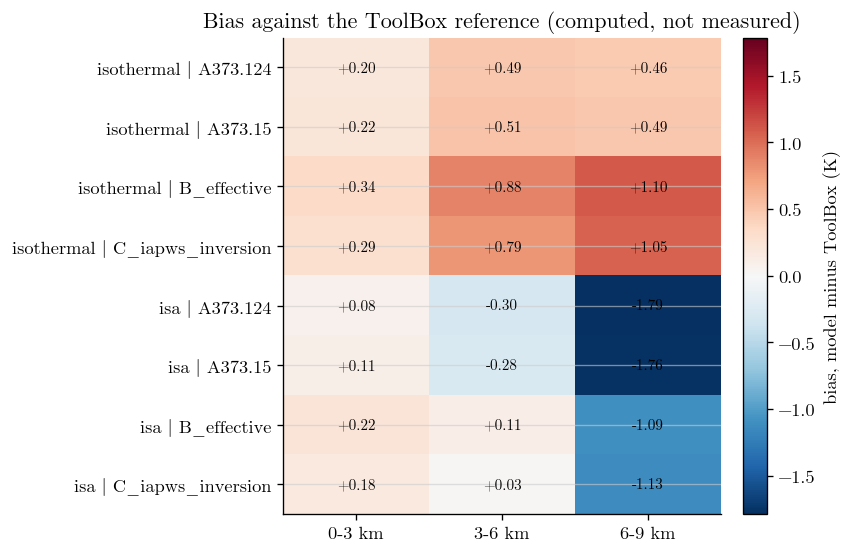

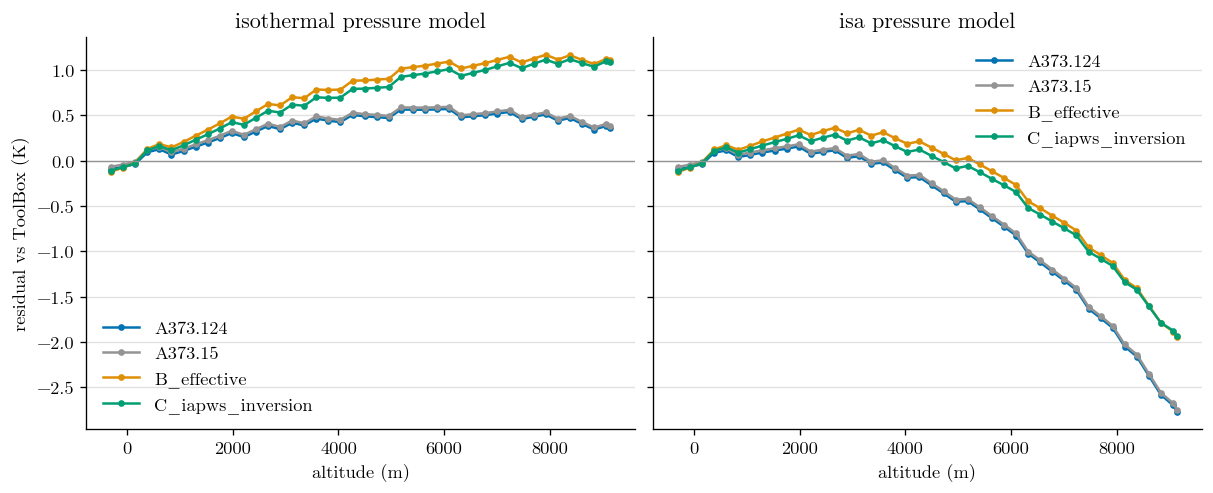

In [13]:
band_out = json.loads((RESULTS / "band_summary.json").read_text())
bs = band_out["band_summary"][REF_TOOLBOX]

# Table: bias (model minus ToolBox reference), K, per band
header = f"{'atmosphere':<12}{'variant':<20}" + "".join(f"{b:>12}" for b in BAND_NAMES)
print(header)
print("-" * len(header))
for a in ATMOS:
    for v in VARIANTS:
        print(f"{a:<12}{v:<20}" + "".join(f"{bs[a][v][b]['bias_K']:>+12.3f}" for b in BAND_NAMES))

# Heatmap of signed bias (RdBu_r), one row per atmosphere and variant
labels = [f"{a} | {v}" for a in ATMOS for v in VARIANTS]
grid = np.array([[bs[a][v][b]["bias_K"] for b in BAND_NAMES] for a in ATMOS for v in VARIANTS])
m = np.abs(grid).max()
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(grid, cmap="RdBu_r", vmin=-m, vmax=m, aspect="auto")
ax.set_xticks(range(len(BAND_NAMES)), BAND_NAMES)
ax.set_yticks(range(len(labels)), labels)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f"{grid[i, j]:+.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="bias, model minus ToolBox (K)")
ax.set_title("Bias against the ToolBox reference (computed, not measured)")
plt.show()

# Residual against altitude for each variant, one panel per pressure model
residuals = json.loads((RESULTS / "residuals.json").read_text())
alts_plot = [r["altitude_m"] for r in residuals["rows"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, a in zip(axes, ATMOS):
    for v in VARIANTS:
        ax.plot(alts_plot, [r["residual_vs_toolbox_K"][a][v] for r in residuals["rows"]], marker="o", ms=3, label=v)
    ax.axhline(0, color=COLOURS["baseline"], lw=0.8)
    ax.set_title(f"{a} pressure model")
    ax.set_xlabel("altitude (m)")
    ax.legend()
axes[0].set_ylabel("residual vs ToolBox (K)")
plt.show()


## Interpreting the results

**What the numbers show (curated subset, 43 altitudes from -305 m to 9144 m).** Every value is model minus a computed reference, so these are agreement statistics, not accuracy against measurement.

- **Atmosphere model dominates.** At 6-9 km the ISA model is about 2.2 K colder than the isothermal model for every variant. There is no sign change of the ISA-minus-isothermal difference between 0 and 9144 m.
- **Isothermal model is biased warm.** At 6-9 km its bias is about +0.46 to +0.49 K for the constant-enthalpy variants and about +1.05 to +1.10 K for the fitted enthalpy (B) and IAPWS inversion (C) variants.
- **ISA model is biased cold.** At 6-9 km its bias is about -1.09 to -1.79 K. Variants B and C remove about 37-39% of that bias (the Z values are written to results/sensitivity.md), and they increase the isothermal bias, because the enthalpy correction moves the same way in both models.
- **Anchor is a minor term.** Moving the anchor from 373.15 K to 373.124 K shifts the 6-9 km bias by about -0.02 K, far smaller than the atmosphere or enthalpy terms.

**Full dependency (not run in this notebook).** The artifact's summary reports ISA 6-9 km biases of -1.03 to -1.72 K and isothermal biases of +0.47 to +1.10 K for all 125 altitudes in the full dependency file. The curated subset here gives the same isothermal range and somewhat larger ISA magnitudes (-1.09 to -1.79 K), so the subset is a demonstration, not a substitute for the full set.

**What this means for the claim.** Against computed references, the simple barometric formula is off by roughly 1-2 K at 6-9 km in the ISA case. Most of that comes from the choice of atmosphere model, not from the boiling-point relation. The check that reproduces the IAPWS reference (check 5) and the sea-level inversion pass, so the code is consistent with the references it uses. The result does not show how well the formula matches measured boiling points, because no measured values are in the dataset. Variant B is fitted to the same IAPWS curve as the reference, so its agreement is not independent.